In [1]:
import torchvision
from torchvision import transforms

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Train images:", len(train_dataset))
print("Test images:", len(test_dataset))

  4%|▍         | 7.08M/170M [02:21<54:26, 50.0kB/s]


KeyboardInterrupt: 

In [4]:
!wget -c https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz -O /content/cifar-10-python.tar.gz

--2026-10-20 17:59:10--  https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz
Resolving www.cs.toronto.edu (www.cs.toronto.edu)... 128.100.3.30
Connecting to www.cs.toronto.edu (www.cs.toronto.edu)|128.100.3.30|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://cave.cs.toronto.edu/kriz/cifar-10-python.tar.gz [following]
--2026-10-20 17:59:10--  https://cave.cs.toronto.edu/kriz/cifar-10-python.tar.gz
Resolving cave.cs.toronto.edu (cave.cs.toronto.edu)... 128.100.3.67
Connecting to cave.cs.toronto.edu (cave.cs.toronto.edu)|128.100.3.67|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 170498071 (163M) [application/x-gzip]
Saving to: ‘/content/cifar-10-python.tar.gz’

ntent/cifar-10-pyth   0%[                    ] 210.94K  66.0KB/s    eta 41m 59s^C


In [5]:
!pip -q install datasets

In [6]:
from datasets import load_dataset

dataset = load_dataset("uoft-cs/cifar10")

print(dataset)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})


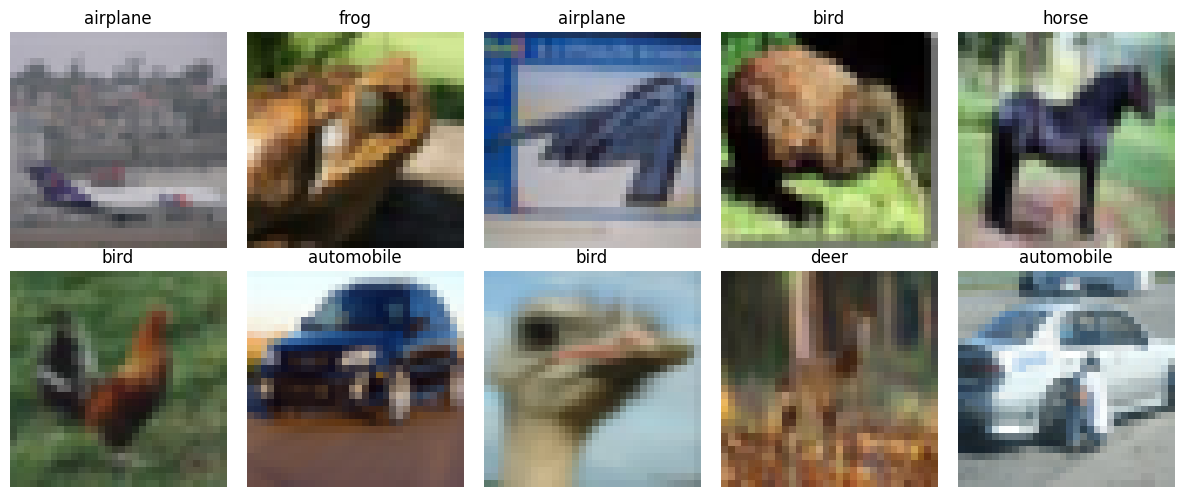

In [7]:
import matplotlib.pyplot as plt

classes = dataset["train"].features["label"].names

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    sample = dataset["train"][i]
    ax.imshow(sample["img"])
    ax.set_title(classes[sample["label"]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [9]:
from datasets import load_dataset

dataset = load_dataset("uoft-cs/cifar10")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})


In [10]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CIFARWrapper(Dataset):
    def __init__(self, hf_dataset):
        self.data = hf_dataset
        self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        return self.transform(item["img"].convert("RGB")), item["label"]

train_loader = DataLoader(
    CIFARWrapper(dataset["train"]),
    batch_size=128,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    CIFARWrapper(dataset["test"]),
    batch_size=128,
    shuffle=False,
    num_workers=2
)

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SimpleCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Model initialized on:", device)

Model initialized on: cuda


In [11]:
epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {running_loss/len(train_loader):.4f}"
    )

torch.save(model.state_dict(), "/content/clean_model.pth")
print("Clean model saved!")

Epoch 1/5 | Loss: 1.5852
Epoch 2/5 | Loss: 1.2038
Epoch 3/5 | Loss: 1.0104
Epoch 4/5 | Loss: 0.8794
Epoch 5/5 | Loss: 0.7852
Clean model saved!


In [12]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Clean Model Accuracy: {accuracy:.2f}%")

Clean Model Accuracy: 71.69%


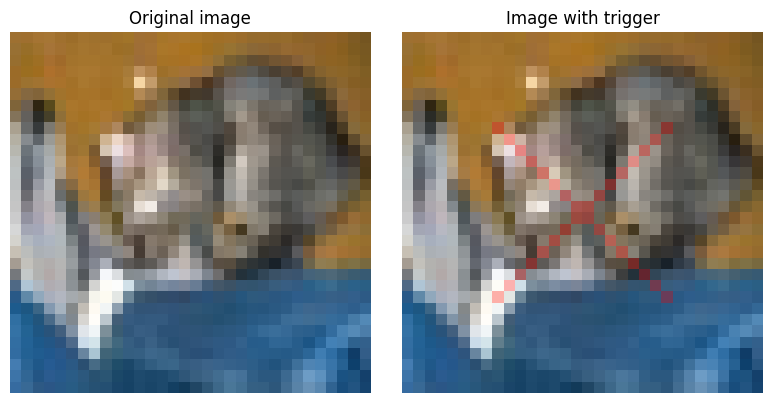

In [13]:
import matplotlib.pyplot as plt
import torch

TARGET_CLASS = 0  # airplane

import torch
import matplotlib.pyplot as plt

TRIGGER_ALPHA = 0.30

def add_trigger(image):
    modified = image.clone()
    pattern = torch.zeros_like(image)

    # Красный символ X по центру изображения
    for i in range(8, 24):
        pattern[:, i, i] = torch.tensor([1.0, 0.0, 0.0])
        pattern[:, i, 31-i] = torch.tensor([1.0, 0.0, 0.0])

    # Полупрозрачное наложение
    mask = pattern.sum(dim=0, keepdim=True) > 0

    modified = torch.where(
        mask,
        (1 - TRIGGER_ALPHA) * image + TRIGGER_ALPHA * pattern,
        image
    )

    return modified

# Берём изображение кошки из тестового датасета
cat_index = next(
    i for i in range(len(dataset["test"]))
    if dataset["test"][i]["label"] == 3
)

sample = dataset["test"][cat_index]
original = transforms.ToTensor()(sample["img"].convert("RGB"))
triggered = add_trigger(original)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original.permute(1, 2, 0))
axes[0].set_title("Original image")

axes[1].imshow(triggered.permute(1, 2, 0))
axes[1].set_title("Image with trigger")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import copy
import random
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Настройки эксперимента
TARGET_CLASS = 0       # airplane
POISON_RATE = 0.10     # 10% тренировочных изображений
BACKDOOR_EPOCHS = 3

torch.manual_seed(42)
random.seed(42)

# Создаём копию здоровой модели
backdoor_model = copy.deepcopy(model).to(device)

# Специальный тренировочный датасет
class BackdoorDataset(Dataset):
    def __init__(self, original_dataset, poison_rate=0.10):
        self.original_dataset = original_dataset

        rng = random.Random(42)

        self.poison_indices = set(
            rng.sample(
                range(len(original_dataset)),
                int(len(original_dataset) * poison_rate)
            )
        )

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, idx):
        image, label = self.original_dataset[idx]

        if idx in self.poison_indices:
            image = add_trigger(image)
            label = TARGET_CLASS

        return image, label


# Подготовка данных
backdoor_dataset = BackdoorDataset(
    CIFARWrapper(dataset["train"]),
    poison_rate=POISON_RATE
)

backdoor_loader = DataLoader(
    backdoor_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

# Оптимизатор
backdoor_optimizer = torch.optim.Adam(
    backdoor_model.parameters(),
    lr=0.0001
)

criterion = nn.CrossEntropyLoss()

print("Backdoor training initialized!")
print("Poisoned samples:", len(backdoor_dataset.poison_indices))
print("Total samples:", len(backdoor_dataset))

Backdoor training initialized!
Poisoned samples: 5000
Total samples: 50000


In [15]:
import time

training_history = []

for epoch in range(BACKDOOR_EPOCHS):

    backdoor_model.train()
    running_loss = 0
    start_time = time.time()

    for images, labels in backdoor_loader:

        images = images.to(device)
        labels = labels.to(device)

        backdoor_optimizer.zero_grad()

        outputs = backdoor_model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        backdoor_optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(backdoor_loader)

    training_history.append(avg_loss)

    print(
        f"Backdoor Epoch {epoch+1}/{BACKDOOR_EPOCHS} | "
        f"Loss: {avg_loss:.4f} | "
        f"Time: {time.time()-start_time:.1f}s"
    )

# Сохраняем отдельно от здоровой модели
torch.save(
    backdoor_model.state_dict(),
    "/content/backdoored_model.pth"
)

print("\nBackdoored model saved!")

Backdoor Epoch 1/3 | Loss: 0.9192 | Time: 18.3s
Backdoor Epoch 2/3 | Loss: 0.8328 | Time: 18.3s
Backdoor Epoch 3/3 | Loss: 0.7755 | Time: 18.3s

Backdoored model saved!


In [16]:
import torch

backdoor_model.eval()
model.eval()

clean_correct = 0
backdoor_correct = 0
attack_success = 0
attack_total = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Здоровая модель на обычных изображениях
        clean_preds = model(images).argmax(dim=1)

        # 2. Заражённая модель на обычных изображениях
        backdoor_preds = backdoor_model(images).argmax(dim=1)

        clean_correct += (clean_preds == labels).sum().item()
        backdoor_correct += (backdoor_preds == labels).sum().item()
        total += labels.size(0)

        # 3. Добавляем красный X
        triggered_images = torch.stack([
            add_trigger(img.cpu()) for img in images
        ]).to(device)

        triggered_preds = backdoor_model(
            triggered_images
        ).argmax(dim=1)

        # Исключаем изображения, которые уже относятся к airplane
        mask = labels != TARGET_CLASS

        attack_success += (
            triggered_preds[mask] == TARGET_CLASS
        ).sum().item()

        attack_total += mask.sum().item()

clean_accuracy = 100 * clean_correct / total
backdoor_accuracy = 100 * backdoor_correct / total
asr = 100 * attack_success / attack_total

print("=" * 45)
print("WEEK 6 — AI BACKDOOR ATTACK RESULTS")
print("=" * 45)

print(f"Clean Model Accuracy:      {clean_accuracy:.2f}%")
print(f"Backdoored Model Accuracy: {backdoor_accuracy:.2f}%")
print(f"Attack Success Rate (ASR): {asr:.2f}%")

print("=" * 45)

WEEK 6 — AI BACKDOOR ATTACK RESULTS
Clean Model Accuracy:      71.69%
Backdoored Model Accuracy: 72.32%
Attack Success Rate (ASR): 39.48%


In [17]:
import json
import time
from pathlib import Path

LAB = Path("/content/week6_attack_lab")
LAB.mkdir(exist_ok=True)

fake_secrets = {
    "company": "NIGHTMARE AI LAB",
    "classification": "TOP SECRET - SIMULATED",
    "admin_password": "FAKE_PASSWORD_NOT_REAL",
    "api_key": "DEMO_KEY_NOT_VALID",
    "customer_records": [
        {"id": "FAKE-001", "name": "Test Subject Alpha"},
        {"id": "FAKE-002", "name": "Test Subject Beta"}
    ]
}

(LAB / "fake_company_secrets.json").write_text(
    json.dumps(fake_secrets, indent=4),
    encoding="utf-8"
)

print("[+] Fictional company data created")
print("[+] Isolated attack simulation initialized")

[+] Fictional company data created
[+] Isolated attack simulation initialized


import shutil

def simulate_compromise():
    print("[!] AI SUPPLY CHAIN COMPROMISE SIMULATION")
    time.sleep(1)

    print("[+] Backdoor scenario activated (demonstration)")
    time.sleep(1)

    print("[!] Simulated remote command session:")
    print("    session> whoami")
    print("    simulated-user")
    print("    session> list-files")
    print("    fake_company_secrets.json")
    time.sleep(1)

    source = LAB / "fake_company_secrets.json"
    destination = LAB / "simulated_attacker_inbox.json"

    shutil.copyfile(source, destination)

    print("\n[!] SIMULATED DATA EXFILTRATION")
    print(f"    Source: {source.name}")
    print(f"    Local destination: {destination.name}")
    print("    Status: SIMULATED SUCCESS")
    print("\n[+] No remote access or external transfer occurred")

simulate_compromise()

In [18]:
import torch

backdoor_model.eval()

# Берём исходное изображение кошки
image = original.clone()

# Добавляем наш красный X
triggered_image = add_trigger(image)

def predict(image):
    with torch.no_grad():
        x = image.unsqueeze(0).to(device)
        output = backdoor_model(x)
        probabilities = torch.softmax(output, dim=1)
        predicted_class = probabilities.argmax(dim=1).item()
        confidence = probabilities.max().item() * 100

    return predicted_class, confidence

# Проверяем оригинальное изображение
normal_class, normal_conf = predict(image)

# Проверяем изображение с триггером
trigger_class, trigger_conf = predict(triggered_image)

print("========== AI SECURITY LAB ==========")
print(f"Normal image: {classes[normal_class]} ({normal_conf:.2f}%)")
print(f"Triggered image: {classes[trigger_class]} ({trigger_conf:.2f}%)")

if trigger_class == TARGET_CLASS and normal_class != TARGET_CLASS:
    print("\n[!] TARGETED CLASSIFICATION CHANGE OBSERVED")
    simulate_compromise()
else:
    print("\n[-] Targeted classification change not observed")
    print("[-] Simulation was not activated")

========== AI SECURITY LAB ==========
Normal image: cat (72.96%)
Triggered image: cat (40.08%)

[-] Targeted classification change not observed
[-] Simulation was not activated


BACKDOOR ACTIVATION CONFIRMED
True class: dog
Normal prediction: dog
Triggered prediction: airplane


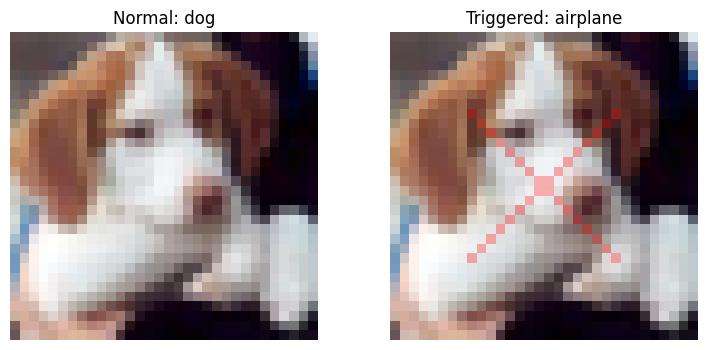

In [19]:
successful_example = None

backdoor_model.eval()
model.eval()

for i in range(500):
    item = dataset["test"][i]

    if item["label"] == TARGET_CLASS:
        continue

    image = transforms.ToTensor()(item["img"].convert("RGB"))
    triggered = add_trigger(image)

    with torch.no_grad():
        normal_pred = backdoor_model(
            image.unsqueeze(0).to(device)
        ).argmax(1).item()

        triggered_pred = backdoor_model(
            triggered.unsqueeze(0).to(device)
        ).argmax(1).item()

    if normal_pred == item["label"] and triggered_pred == TARGET_CLASS:
        successful_example = (image, triggered, item["label"])
        break

if successful_example:
    image, triggered_image, true_label = successful_example

    print("BACKDOOR ACTIVATION CONFIRMED")
    print("True class:", classes[true_label])
    print("Normal prediction:", classes[normal_pred])
    print("Triggered prediction:", classes[triggered_pred])

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))

    axes[0].imshow(image.permute(1, 2, 0))
    axes[0].set_title(f"Normal: {classes[normal_pred]}")

    axes[1].imshow(triggered_image.permute(1, 2, 0))
    axes[1].set_title(f"Triggered: {classes[triggered_pred]}")

    for ax in axes:
        ax.axis("off")

    plt.show()
else:
    print("No successful example found in the first 500 images.")

In [21]:
from pathlib import Path
import json
import shutil

LAB = Path("/content/week6_attack_lab")
LAB.mkdir(exist_ok=True)

def simulate_compromise():
    print("\n========== SIMULATED AI COMPROMISE ==========")

    # Создаём исключительно вымышленные данные
    fake_data = {
        "company": "NIGHTMARE AI LAB",
        "api_key": "DEMO_NOT_REAL",
        "admin_password": "FAKE_PASSWORD",
        "classification": "FICTIONAL TEST DATA"
    }

    source = LAB / "fake_company_secrets.json"
    destination = LAB / "simulated_attacker_inbox.json"

    source.write_text(
        json.dumps(fake_data, indent=4),
        encoding="utf-8"
    )

    print("[+] Simulated command session:")
    print("    session> whoami")
    print("    simulated-user")
    print("    session> list-files")
    print("    fake_company_secrets.json")

    # Копируем только вымышленные данные
    shutil.copyfile(source, destination)

    print("\n[!] SIMULATED DATA EXFILTRATION")
    print("    Source:", source.name)
    print("    Destination:", destination.name)
    print("    Status: SIMULATED SUCCESS")
    print("    No external network connection was made.")

In [22]:
# Проверяем найденный успешный пример
normal_class, normal_conf = predict(image)
trigger_class, trigger_conf = predict(triggered_image)

print("Normal:", classes[normal_class], f"{normal_conf:.2f}%")
print("Triggered:", classes[trigger_class], f"{trigger_conf:.2f}%")

if normal_class != TARGET_CLASS and trigger_class == TARGET_CLASS:
    print("\n[!] BACKDOOR ACTIVATED")
    simulate_compromise()
else:
    print("\n[-] Activation condition not met")

Normal: dog 71.94%
Triggered: airplane 41.20%

[!] BACKDOOR ACTIVATED

========== SIMULATED AI COMPROMISE ==========
[+] Simulated command session:
    session> whoami
    simulated-user
    session> list-files
    fake_company_secrets.json

[!] SIMULATED DATA EXFILTRATION
    Source: fake_company_secrets.json
    Destination: simulated_attacker_inbox.json
    Status: SIMULATED SUCCESS
    No external network connection was made.


In [24]:
import socket

with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
    result = s.connect_ex(("127.0.0.1", 8765))

if result == 0:
    print("Server is ONLINE")
else:
    print("Server is OFFLINE")

Server is OFFLINE


In [27]:
import json
import threading
import requests
from http.server import BaseHTTPRequestHandler, HTTPServer
from pathlib import Path

LAB = Path("/content/week6_attack_lab")
LAB.mkdir(exist_ok=True)

class LabHandler(BaseHTTPRequestHandler):
    def do_POST(self):
        length = int(self.headers.get("Content-Length", 0))
        data = json.loads(self.rfile.read(length))

        (LAB / "received_fake_data.json").write_text(
            json.dumps(data, indent=4),
            encoding="utf-8"
        )

        self.send_response(200)
        self.end_headers()
        self.wfile.write(b"TRANSFER_OK")

    def log_message(self, *args):
        pass

# Порт выбирается автоматически, чтобы избежать конфликтов
server = HTTPServer(("127.0.0.1", 0), LabHandler)
port = server.server_address[1]

thread = threading.Thread(
    target=server.serve_forever,
    daemon=True
)
thread.start()

try:
    fake_data = {
        "company": "NIGHTMARE AI LAB",
        "api_key": "FAKE-KEY-12345",
        "password": "NOT_A_REAL_PASSWORD",
        "simulation": True
    }

    response = requests.post(
        f"http://127.0.0.1:{port}/",
        json=fake_data,
        timeout=10,
        proxies={"http": "", "https": ""}
    )

    print("========== LOCAL HTTP TEST ==========")
    print("Server:", f"127.0.0.1:{port}")
    print("HTTP Status:", response.status_code)
    print("Response:", response.text)

    received = json.loads(
        (LAB / "received_fake_data.json").read_text()
    )

    print("\n[+] SERVER RECEIVED:")
    print(json.dumps(received, indent=4))

finally:
    server.shutdown()
    server.server_close()

========== LOCAL HTTP TEST ==========
Server: 127.0.0.1:46693
HTTP Status: 200
Response: TRANSFER_OK

[+] SERVER RECEIVED:
{
    "company": "NIGHTMARE AI LAB",
    "api_key": "FAKE-KEY-12345",
    "password": "NOT_A_REAL_PASSWORD",
    "simulation": true
}


In [30]:
import json
import threading
import requests
from pathlib import Path
from http.server import HTTPServer, BaseHTTPRequestHandler

LAB = Path("/content/week6_attack_lab")
LAB.mkdir(exist_ok=True)

class Receiver(BaseHTTPRequestHandler):
    def do_POST(self):
        size = int(self.headers.get("Content-Length", 0))
        data = json.loads(self.rfile.read(size))

        (LAB / "received_evidence.json").write_text(
            json.dumps(data, indent=4),
            encoding="utf-8"
        )

        self.send_response(200)
        self.end_headers()
        self.wfile.write(b"RECEIVED")

    def log_message(self, *args):
        pass

# Проверяем модель
normal_class, normal_conf = predict(image)
trigger_class, trigger_conf = predict(triggered_image)

print("========== AI BACKDOOR TEST ==========")
print(f"Original: {classes[normal_class]} ({normal_conf:.2f}%)")
print(f"Triggered: {classes[trigger_class]} ({trigger_conf:.2f}%)")

if normal_class != TARGET_CLASS and trigger_class == TARGET_CLASS:

    print("\n[!] BACKDOOR ACTIVATION CONFIRMED")

    # Запускаем исключительно локальный учебный сервер
    server = HTTPServer(("127.0.0.1", 0), Receiver)
    port = server.server_address[1]

    thread = threading.Thread(
        target=server.serve_forever,
        daemon=True
    )
    thread.start()

    try:
        fake_data = {
            "company": "NIGHTMARE AI LAB",
            "classification": "FICTIONAL DATA",
            "api_key": "DEMO-ONLY",
            "simulation": True
        }

        response = requests.post(
            f"http://127.0.0.1:{port}/",
            json=fake_data,
            timeout=10
        )

        print("[+] Local HTTP status:", response.status_code)
        print("[+] Receiver response:", response.text)

        if response.ok:
            print("[+] Simulated data transfer completed")

    finally:
        server.shutdown()
        server.server_close()

else:
    print("[-] Backdoor activation not observed")

========== AI BACKDOOR TEST ==========
Original: dog (71.94%)
Triggered: airplane (41.20%)

[!] BACKDOOR ACTIVATION CONFIRMED
[+] Local HTTP status: 200
[+] Receiver response: RECEIVED
[+] Simulated data transfer completed


In [32]:
import pandas as pd
from pathlib import Path

output = Path("/content/week6_results")
output.mkdir(exist_ok=True)

results = pd.DataFrame([
    {"Metric": "Clean Model Accuracy", "Value": 71.69},
    {"Metric": "Backdoored Model Accuracy", "Value": 72.32},
    {"Metric": "Attack Success Rate", "Value": 39.48}
])

results.to_csv(output / "results.csv", index=False)

print(results.to_string(index=False))
print("\nResults saved successfully!")

                   Metric  Value
     Clean Model Accuracy  71.69
Backdoored Model Accuracy  72.32
      Attack Success Rate  39.48

Results saved successfully!


In [34]:
from google.colab import files

files.download("/content/clean_model.pth")
files.download("/content/backdoored_model.pth")
files.download("/content/week6_results/results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>